In [1]:
from IPython import display
import ultralytics

In [2]:
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [3]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

In [4]:
display.clear_output()
ultralytics.checks()

Ultralytics 8.4.174  Python-3.13.15 torch-2.14.1+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
Setup complete  (16 CPUs, 31.7 GB RAM, 292.5/465.7 GB disk)


In [5]:
# ตรวจสอบจำนวนวัตถุใน Dataset (เงื่อนไข Train >= 100 object ต่อ class)
CLASSES = {0: "Bird", 1: "Cat", 2: "Dog", 3: "Horse", 4: "Cow"}

for split in ["train", "val"]:
    labels = sorted(Path(f"dataset/animals_rec/labels/{split}").glob("*.txt"))
    counts = Counter()
    for lf in labels:
        for line in lf.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    print(f"{split}: {len(labels)} images")
    for i, n in CLASSES.items():
        print(f"  {n:7s} {counts[i]:4d} objects")
    print()

train: 293 images
  Bird      97 objects
  Cat      115 objects
  Dog      115 objects
  Horse    116 objects
  Cow      114 objects

val: 164 images
  Bird     123 objects
  Cat       25 objects
  Dog       45 objects
  Horse     69 objects
  Cow      124 objects



In [6]:
# 1. เทรน Bounding Box (Rec) - Freeze backbone
model_rec = ultralytics.YOLO("yolo26n.yaml").load("yolo26n.pt")
model_rec.train(
    data="animals_rec.yaml",
    epochs=15,
    batch=16,
    imgsz=640,
    freeze=10,
    name="animals_rec",
    exist_ok=True,
    workers=2
)

Transferred 708/708 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.199 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.174  Python-3.13.15 torch-2.14.1+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=animals_rec.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, m

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000185CF2656D0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
    

In [7]:
# 2. เทรน Polygon Segmentation (Poly) - Freeze backbone
model_poly = ultralytics.YOLO("yolo26n-seg.yaml").load("yolo26n-seg.pt")
model_poly.train(
    data="animals_poly.yaml",
    epochs=15,
    batch=16,
    imgsz=640,
    freeze=10,
    name="animals_poly",
    exist_ok=True,
    workers=2
)

Transferred 844/844 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.199 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.174  Python-3.13.15 torch-2.14.1+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=animals_poly.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, 

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000185CF912B30>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.0400


image 1/1 d:\lab\Lab_index\moth10\project_yolozoo\dataset\animals_poly\images\val\000000001675.jpg: 480x640 2 Cats, 146.1ms
Speed: 5.3ms preprocess, 146.1ms inference, 7.0ms postprocess per image at shape (1, 3, 480, 640)
Cat     conf: 0.54  bbox: [2, 12, 640, 312]
Cat     conf: 0.46  bbox: [37, 91, 640, 310]


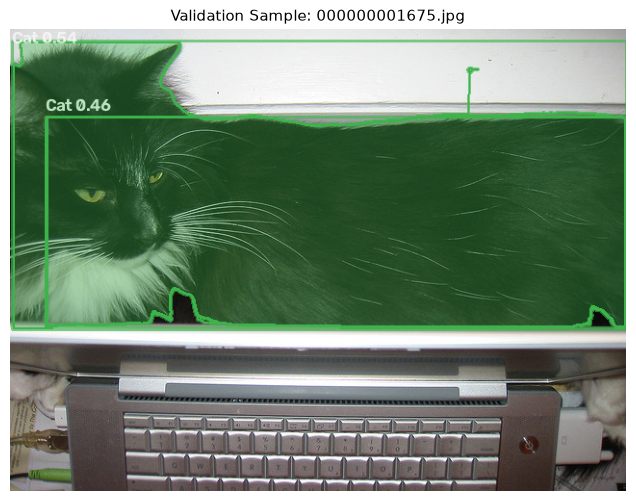

In [8]:
# โหลดโมเดลมาทดสอบ Predict (รูปตัวอย่างในชุด val พร้อมพล็อตแสดงผลทั้ง Box และ Polygon Mask)
import glob
import numpy as np

model = ultralytics.YOLO("weights/best_poly.pt")
imgs = sorted(glob.glob("dataset/animals_poly/images/val/*.jpg"))
img_path = imgs[0]

result = model.predict(img_path)[0]
im = cv2.imread(img_path)
overlay = im.copy()

# สีกรอบแยก 5 คลาส (BGR)
COLOR_MAP = {
    "Bird":  (80, 80, 255),
    "Cat":   (75, 180, 60),
    "Dog":   (0, 140, 255),
    "Horse": (255, 130, 0),
    "Cow":   (200, 50, 200)
}

for i, box in enumerate(result.boxes):
    cls_name = result.names[int(box.cls[0].item())]
    x0, y0, x1, y1 = [round(x) for x in box.xyxy[0].tolist()]
    cf = round(box.conf[0].item(), 2)
    color = COLOR_MAP.get(cls_name, (0, 255, 0))
    
    # วาด Polygon Mask หากมี
    if result.masks is not None and i < len(result.masks.xy):
        pts = result.masks.xy[i].astype(np.int32).reshape(-1, 1, 2)
        cv2.fillPoly(overlay, [pts], color)
        cv2.polylines(im, [pts], True, color, 2)
        
    # วาด Bounding Box และ Label
    cv2.rectangle(im, (x0, y0), (x1, y1), color, 2)
    label = f"{cls_name} {cf}"
    cv2.putText(im, label, (x0, max(y0 - 6, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
    print(f"{cls_name:7s} conf: {cf:.2f}  bbox: [{x0}, {y0}, {x1}, {y1}]")

cv2.addWeighted(overlay, 0.35, im, 0.65, 0, im)
plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
plt.title(f"Validation Sample: {Path(img_path).name}", fontsize=11)
plt.axis("off")
plt.show()

In [12]:
# รัน Predict ทุกรูปใน val -> สรุปสถิติและส่งออกไฟล์ CSV 
import csv

OUT = Path("runs/predict_val")
OUT.mkdir(parents=True, exist_ok=True)
csv_path = OUT / "predict_results.csv"

rows = []
for path in imgs:
    res = model.predict(path, verbose=False)[0]
    fname = Path(path).name
    for box in res.boxes:
        name = res.names[int(box.cls[0].item())]
        x0, y0, x1, y1 = [round(v) for v in box.xyxy[0].tolist()]
        cf = round(box.conf[0].item(), 4)
        rows.append([fname, name, cf, x0, y0, x1, y1])

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["image", "class", "conf", "x0", "y0", "x1", "y1"])
    w.writerows(rows)

class_counts = Counter(r[1] for r in rows)

print("=" * 60)
print("🎯 ผลการทดสอบทำนายภาพทั้งหมดในชุด Validation")
print("=" * 60)
print(f"📁 จำนวนรูปภาพทดสอบทั้งหมด : {len(imgs):>4d} ภาพ")
print(f"🔍 ตรวจพบวัตถุทั้งหมด        : {len(rows):>4d} รายการ")
print(f"💾 บันทึกตารางสรุปผลไว้ที่   : {csv_path}")
print("-" * 60)
print("📊 สรุปจำนวนวัตถุที่ตรวจพบแยกตามชนิดสัตว์:")
for name, n in class_counts.most_common():
    print(f"  {name:7s} {n:4d}")
print("=" * 60)

# ตัวอย่าง 5 แถวแรก
print("image | class | conf | x0 y0 x1 y1")
for r in rows[:5]:
    print(" | ".join(str(v) for v in r))

🎯 ผลการทดสอบทำนายภาพทั้งหมดในชุด Validation
📁 จำนวนรูปภาพทดสอบทั้งหมด :  167 ภาพ
🔍 ตรวจพบวัตถุทั้งหมด        :  379 รายการ
💾 บันทึกตารางสรุปผลไว้ที่   : runs\predict_val\predict_results.csv
------------------------------------------------------------
📊 สรุปจำนวนวัตถุที่ตรวจพบแยกตามชนิดสัตว์:
  Cow      136
  Bird      88
  Horse     71
  Dog       58
  Cat       26
image | class | conf | x0 y0 x1 y1
000000001675.jpg | Cat | 0.5352 | 2 | 12 | 640 | 312
000000001675.jpg | Cat | 0.4606 | 37 | 91 | 640 | 310
000000002923.jpg | Bird | 0.5321 | 135 | 238 | 146 | 252
000000019042.jpg | Bird | 0.9 | 307 | 166 | 330 | 204
000000019042.jpg | Bird | 0.6911 | 206 | 239 | 247 | 263
